# Домашнее задание 1. Рекомендательные системы

Новиков Кирилл Сергеевич, Б05-307.

Сравниваю персональные top-10 рекомендации на Amazon Video Games: item-kNN, iALS, EASE, FM с категориями и ALS с собственным таргетом. Рекомендуемый объект — товар из раздела Video Games, в том числе игра или аксессуар. Релевантность во всех экспериментах одна: будущая оценка не ниже 4.

На test EASE и iALS дали почти одинаковый результат: NDCG@10 около 0.0507. Собственный таргет оказался хуже базового, а прибавка от категорий FM неустойчива по bootstrap. Точные значения и ограничения — в разделах 5–6.

## 1. Данные и запуск

Нужен Python 3.12. Из корня репозитория:

```bash
python -m venv .venv
source .venv/bin/activate
pip install -r hw1/requirements.txt
cd hw1
jupyter lab experiments.ipynb
```

Дальше выполнить все ячейки по порядку. Для запуска без интерфейса:

```bash
jupyter nbconvert --execute --to notebook --inplace --ExecutePreprocessor.timeout=3600 experiments.ipynb
```

Архивы автоматически скачиваются в `data/`, около 131 МБ суммарно. В GitHub они не загружаются. На CPU полный запуск занимает несколько минут; точное время зависит от компьютера. Все модели учатся с нуля, готовых рекомендательных библиотек нет.

In [1]:
import os
from pathlib import Path

if not Path('models').exists() and Path('hw1/models').exists():
    os.chdir('hw1')

import gc
import json
import random
import platform
from time import perf_counter
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import torch
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown

from models import KNN, IALS, EASE, FM, CustomALS
from utils import load_data, prepare, matrix, truth, recommend, evaluate, interval

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
limit = threadpool_limits(limits=1)
pd.set_option('display.max_colwidth', 90)
plt.rcParams.update({'figure.figsize': (10, 4.5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': False, 'figure.dpi': 110})
Path('figures').mkdir(exist_ok=True)

t1 = int(pd.Timestamp('2013-01-01', tz='UTC').timestamp())
t2 = int(pd.Timestamp('2014-01-01', tz='UTC').timestamp())
cfg = {'seed': seed, 'items': 3000, 'min_train': 3, 'max_eval_users': 3000,
       'k': 10, 'train_until': '2013-01-01', 'validation_until': '2014-01-01'}
display(pd.Series(cfg, name='Параметры'))
display(pd.Series({s: version(s) for s in ['numpy', 'scipy', 'pandas', 'torch',
                                         'matplotlib', 'nbformat', 'nbclient']}, name='Версии'))
print('Python:', platform.python_version(), '| CPU:', platform.machine())

seed                        42
items                     3000
min_train                    3
max_eval_users            3000
k                           10
train_until         2013-01-01
validation_until    2014-01-01
Name: Параметры, dtype: object

numpy          2.5.4
scipy         1.18.1
pandas         3.1.0
torch         2.15.0
matplotlib    3.11.2
nbformat      5.11.1
nbclient      0.11.0
Name: Версии, dtype: str

Python: 3.12.14 | CPU: arm64


Использую **Amazon Product Data (2014), Video Games, 5-core**.

- [Первоисточник UCSD](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon/links.html)
- [Отзывы](https://snap.stanford.edu/data/amazon/productGraph/categoryFiles/reviews_Video_Games_5.json.gz)
- [Метаданные](https://snap.stanford.edu/data/amazon/productGraph/categoryFiles/meta_Video_Games.json.gz)

В исходной версии 231 780 отзывов. `reviewerID` — пользователь, `asin` — товар, `overall` — оценка от 1 до 5, `unixReviewTime` — время отзыва в секундах UTC. Отзыв считаю наблюдаемым взаимодействием, а не доказательством покупки. Из метаданных беру название для просмотра рекомендаций и категории для FM. Текст отзыва, helpfulness, текущие цены, salesRank и связи also_bought не использую.

In [2]:
raw, meta, hashes = load_data()
display(pd.DataFrame({'SHA-256': hashes}))
display(pd.DataFrame({'строки': [len(raw), len(meta)],
                      'уникальные пользователи': [raw.user.nunique(), None],
                      'уникальные товары': [raw.item.nunique(), meta.item.nunique()]},
                     index=['Отзывы', 'Метаданные']))
display(raw.head(3))

,SHA-256
reviews_Video_Games_5.json.gz,035690169fa2bba30cd0ae0c3e7dbf7bc58efde65fc1742a9ce85986e283b09c
meta_Video_Games.json.gz,b7bf4c724632874b931056e48957775822c6f0c9092f5bbf2d449694bec36180


,строки,уникальные пользователи,уникальные товары
Отзывы,231780,24303.0,10672
Метаданные,50953,NaN,50953


,user,item,r,t
0,A2HD75EMZR8QLN,0700099867,1.0,1341792000
1,A3UR8NLLY1ZHCX,0700099867,4.0,1372550400
2,A1INA0F5CWW3J4,0700099867,1.0,1403913600


## 2. EDA и подготовка

Удаляю пропуски в обязательных полях и некорректные оценки/даты. Для повторной пары пользователь–товар сохраняю самый ранний отзыв: так поздняя оценка не заменит раннюю в train. Затем беру 3 000 товаров с наибольшим числом **обучающих** отзывов, при равенстве сортирую по ASIN. Оставляю пользователей хотя бы с тремя обучающими отзывами после ограничения каталога. Фильтр пользователей тоже не смотрит в будущее.

Размер каталога ограничен из-за плотной матрицы EASE. Это сравнение на относительно популярных товарах, а не на полном ассортименте. Пустые категории заменяю `Unknown`, отсутствующие названия — ASIN. Пропуски метаданных не удаляют взаимодействия.

In [3]:
display(raw.isna().sum().rename('Пропуски'))
print('Повторные пары user/item:', raw.duplicated(['user', 'item']).sum())
print('Оценки вне [1, 5]:', (~raw.r.between(1, 5)).sum())
print('Некорректные timestamps:', ((raw.t <= 0) | raw.t.isna()).sum())
display(pd.Series({'Нет названия': meta.title.isna().sum(),
                   'Нет категорий': meta.cats.map(len).eq(0).sum(),
                   'Повторные ASIN в метаданных': meta.item.duplicated().sum()}))

df, items, cats, tr, va, te, cleaning = prepare(raw, meta, t1, t2, n=cfg['items'])
shape = (df.u.nunique(), df.i.nunique())
display(cleaning)
display(pd.Series({'Разреженность итоговой матрицы': 1 - len(df) / np.prod(shape),
                   'Доля товаров без исходного названия': (items.title == items.item).mean(),
                   'Доля товаров с Unknown': items.cats.map(lambda x: x == ['Unknown']).mean(),
                   'Число категорий': len({s for x in items.cats for s in x})}))
del raw, meta
gc.collect();

user    0
item    0
r       0
t       0
Name: Пропуски, dtype: int64

Повторные пары user/item: 0
Оценки вне [1, 5]: 0
Некорректные timestamps: 0


Нет названия                   48688
Нет категорий                    416
Повторные ASIN в метаданных        0
dtype: int64

,этап,взаимодействия,пользователи,товары
0,Исходные отзывы,231780,24303,10672
1,Очистка и 3 000 товаров по train,141359,23406,3000
2,Пользователи с >=3 отзывами в train,110416,14040,3000


Разреженность итоговой матрицы           0.997379
Доля товаров без исходного названия      0.985000
Доля товаров с Unknown                   0.006667
Число категорий                        133.000000
dtype: float64

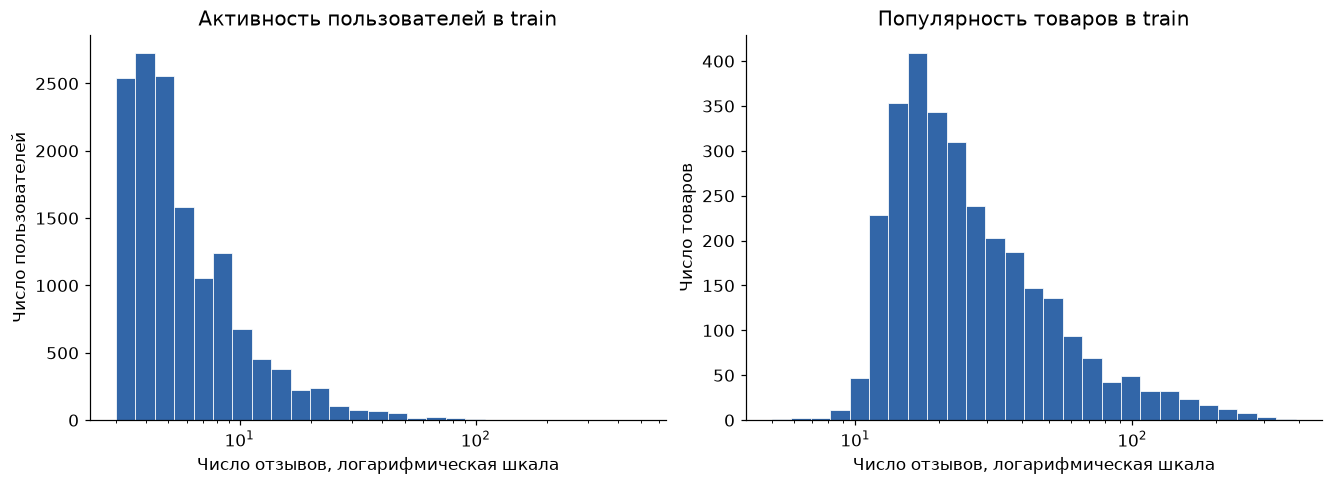

count    14040.000000
mean         7.358547
std          9.762064
min          3.000000
25%          4.000000
50%          5.000000
75%          8.000000
max        494.000000
Name: Отзывы пользователя в train, dtype: float64

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3), layout='constrained')
for a, s, title in [(ax[0], tr.groupby('u').size(), 'Активность пользователей в train'),
                    (ax[1], tr.groupby('i').size(), 'Популярность товаров в train')]:
    bins = np.geomspace(max(1, s.min()), s.max() + 1, 28)
    a.hist(s, bins=bins, color='#3266a8', edgecolor='white', linewidth=.5)
    a.set_xscale('log')
    a.set_xlabel('Число отзывов, логарифмическая шкала')
    a.set_ylabel('Число пользователей' if a is ax[0] else 'Число товаров')
    a.set_title(title)
fig.savefig('figures/activity.png', bbox_inches='tight')
plt.show()
display(tr.groupby('u').size().describe().rename('Отзывы пользователя в train'))

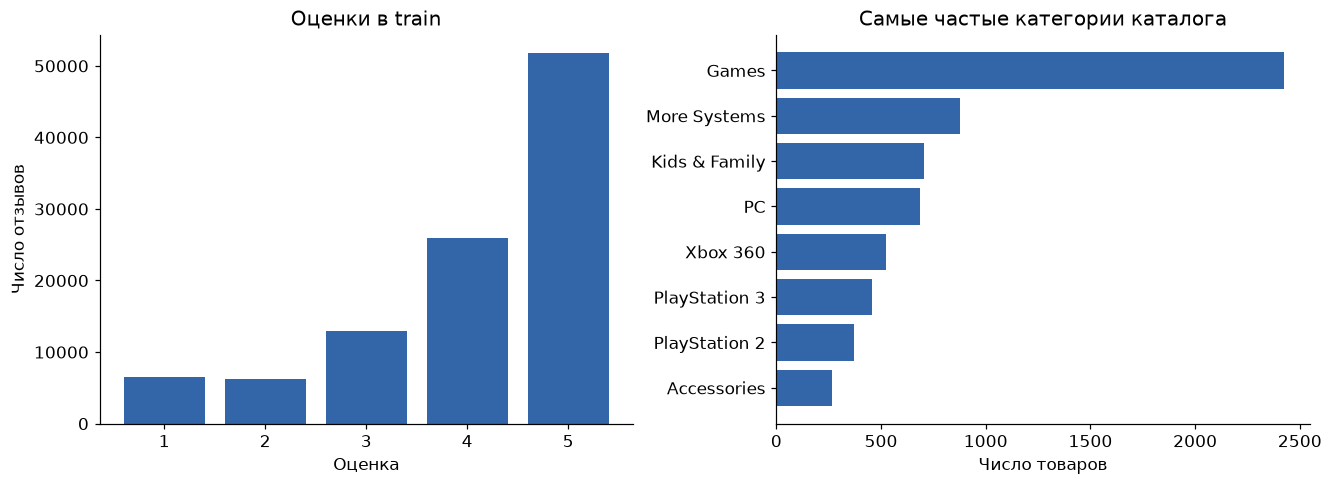

Доля положительных отзывов в train: 0.7516
Категории пересекаются: один товар может входить в несколько категорий.


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3), layout='constrained')
s = tr.r.value_counts().sort_index()
ax[0].bar(s.index.astype(int).astype(str), s.values, color='#3266a8')
ax[0].set(title='Оценки в train', xlabel='Оценка', ylabel='Число отзывов')
s = items.cats.explode().value_counts().head(8).sort_values()
ax[1].barh(s.index, s.values, color='#3266a8')
ax[1].set(title='Самые частые категории каталога', xlabel='Число товаров')
fig.savefig('figures/metadata.png', bbox_inches='tight')
plt.show()
print('Доля положительных отзывов в train:', round(tr.r.ge(4).mean(), 4))
print('Категории пересекаются: один товар может входить в несколько категорий.')

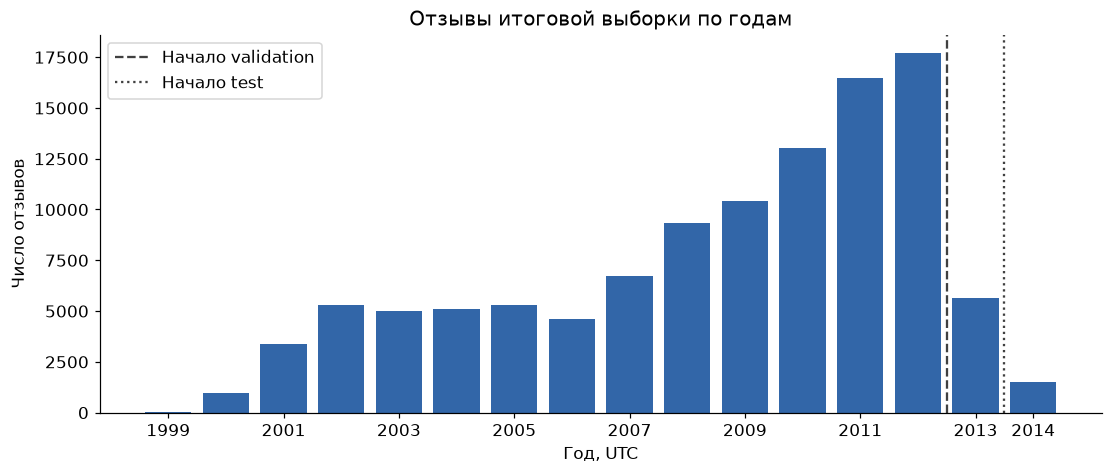

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.2), layout='constrained')
s = df.assign(year=pd.to_datetime(df.t, unit='s', utc=True).dt.year).groupby('year').size()
ax.bar(s.index, s.values, color='#3266a8')
ax.axvline(2012.5, color='#404040', linestyle='--', label='Начало validation')
ax.axvline(2013.5, color='#404040', linestyle=':', label='Начало test')
ax.set(title='Отзывы итоговой выборки по годам', xlabel='Год, UTC', ylabel='Число отзывов')
ax.set_xticks(sorted(set(range(int(s.index.min()), int(s.index.max()) + 1, 2)) | {int(s.index.max())}))
ax.legend()
fig.savefig('figures/time.png', bbox_inches='tight')
plt.show()

У распределений активности и популярности длинный правый хвост: медиана активности в train — 5 отзывов, максимум — 494. Оценки 4–5 составляют 75.16% train, поэтому отрицательных наблюдений заметно меньше. Категория Games покрывает большую часть каталога; более узкие платформы могут быть полезнее для персонализации. Временной график также показывает, что после фильтров основная масса данных остаётся в train.

## 3. Протокол оценки

Train — отзывы до 01.01.2013, validation — 2013 год, test — с 01.01.2014 до конца датасета. Даты фиксированы, временные границы общие для всех пользователей. Нет ситуации, когда поздний отзыв одного пользователя обучает модель для более раннего запроса другого.

Каталог фиксирую по train: все 3 000 товаров уже были известны до первой границы. Новые пользователи и товары вне этого каталога не оцениваются; их число показано в таблице очистки в совокупности с остальными исключениями. Это warm-start постановка. Релевантные товары — все оценки ≥4 в соответствующем будущем периоде. Из релевантных и кандидатов исключаю всё, что пользователь уже оценивал, включая низкие оценки.

Кандидаты — **весь фиксированный каталог**, кроме известных пользователю товаров. Отрицательные кандидаты для оценки не сэмплируются. Пользователей с хотя бы одним доступным релевантным товаром выбираю отдельно для validation и test; если их больше 3 000, беру случайные 3 000 без возвращения с seed=42. Когорта внутри этапа общая для всех моделей и обеих абляций. При равных scores порядок задаётся внутренним item ID, соответствующим сортировке ASIN.

До подбора выбираю **NDCG@10** основной метрикой: важно поставить подходящий товар ближе к началу. Вторая метрика — **Recall@10**: какую часть будущих понравившихся товаров удалось показать. Усреднение по пользователям, а не по отзывам:

$$
Recall@10_u=\frac{|R_u^{10}\cap G_u|}{|G_u|},\quad
DCG@10_u=\sum_{j=1}^{10}\frac{\mathbb{1}[R_{uj}\in G_u]}{\log_2(j+1)},\quad
NDCG@10_u=\frac{DCG@10_u}{\sum_{j=1}^{\min(10,|G_u|)}1/\log_2(j+1)}.
$$

Настройки выбираю только по validation NDCG@10. После выбора переобучаю на train+validation и один раз сравниваю на test. На test исключаю уже всю историю train+validation. Критерий релевантности от модели и её обучающего таргета не зависит.

In [7]:
display(pd.DataFrame([{'Часть': name, 'Отзывы': len(a), 'Пользователи': a.u.nunique(),
                       'Товары': a.i.nunique(),
                       'Начало UTC': str(pd.to_datetime(a.t.min(), unit='s', utc=True).date()),
                       'Конец UTC': str(pd.to_datetime(a.t.max(), unit='s', utc=True).date())}
                      for name, a in [('train', tr), ('validation', va), ('test', te)]]))
ar = matrix(tr, shape)
ap = matrix(tr, shape, positive=True)
vu, vq = truth(va, ar, cfg['max_eval_users'], seed)
print('Пользователей в validation:', len(vu))
print('Минимум кандидатов:', min(shape[1] - ar[u].nnz for u in vu))
assert len(vu) > 0 and min(shape[1] - ar[u].nnz for u in vu) >= 10

,Часть,Отзывы,Пользователи,Товары,Начало UTC,Конец UTC
0,train,103314,14040,3000,1999-10-14,2012-12-31
1,validation,5618,2440,1559,2013-01-01,2013-12-31
2,test,1484,795,817,2014-01-01,2014-07-16


Пользователей в validation: 2015
Минимум кандидатов: 2506


## 4. Модели и подбор параметров

### Item-kNN

Пусть $A_{ui}=1$, если обучающая оценка ≥4, иначе 0. Использую cosine similarity со shrinkage:

$$
s_{ij}=\frac{(A^TA)_{ij}}{\sqrt{(A^TA)_{ii}(A^TA)_{jj}}+h},\quad s_{ii}=0,
\qquad \hat r_{ui}=\sum_{j\in N_k(i)}s_{ij}A_{uj}.
$$

Для каждого целевого товара храню k ближайших соседей. Нормировки по пользователю нет. Подбираю k из {30, 100}, h=10.

### iALS

Для наблюдаемой пары $p_{ui}=\mathbb{1}[r_{ui}\ge4]$, для ненаблюдаемой 0. Confidence $c_{ui}=1+\alpha\mathbb{1}[(u,i)\text{ наблюдалась}]$. Низкие оценки имеют повышенный confidence при нулевом таргете.

$$
L=\sum_{ui}c_{ui}(p_{ui}-x_u^Ty_i)^2+\lambda(\|X\|_F^2+\|Y\|_F^2),
\quad
x_u=(Y^TC_uY+\lambda I)^{-1}Y^TC_up_u.
$$

Чередую точные решения для пользователей и товаров; отрицательные ненаблюдаемые пары учитываются через $Y^TY$, а не перечисляются. Score — скалярное произведение факторов. k=32, α=20, 12 итераций, λ из {1, 10}.

### EASE

$$
\min_B\|A-AB\|_F^2+\lambda\|B\|_F^2,\quad \operatorname{diag}(B)=0.
$$

$P=(A^TA+\lambda I)^{-1}$, $B_{ij}=-P_{ij}/P_{jj}$ для i≠j, диагональ нулевая. Score — строка $AB$. λ из {100, 500}. Обратная матрица вычисляется через решение системы с Cholesky.

### FM с категориями

Признаки — one-hot user ID, item ID и multi-hot категории товара. Они дают взаимодействия пользователя с платформой/категорией и позволяют разделять информацию между товарами. Признаки товара фиксируются для каталога, известного в train; пользовательская статистика из будущего не используется. Название нужно только для просмотра результатов.

$$
\hat z=w_0+\sum_jw_jf_j+\frac12\sum_{d=1}^{k}\left[(\sum_jv_{jd}f_j)^2-\sum_jv_{jd}^2f_j^2\right].
$$

Обучаю бинарной кросс-энтропией: для наблюдаемых пар label=1 при оценке ≥4, иначе 0. На каждый положительный отзыв добавляю одну ненаблюдаемую пару с label=0. Negative sampling проверяет **всю обучающую историю** пользователя; будущие взаимодействия не подсматривает. Отрицательные пары пересэмплируются каждую эпоху. Использую Adam и autograd PyTorch, саму FM и вычисление scores реализую самостоятельно. k=32, 10 эпох, weight decay=1e-5, lr из {0.005, 0.02}, batch=4096. Отдельно проверю FM только с ID при тех же выбранных настройках.

### ALS с собственным целевым сигналом

$$
q_{ui}=\begin{cases}(r_{ui}-3)/2,&(u,i)\text{ наблюдалась},\\0,&\text{иначе}.\end{cases}
$$

Оценкам 1, 2, 3, 4, 5 соответствуют таргеты −1, −0.5, 0, 0.5, 1. Положительная история отличается по силе предпочтения, а низкая оценка прямо отталкивает от похожих товаров. В базовом iALS оценки 1 и 2 обе имеют нулевой таргет, а 4 и 5 — единичный. Здесь меняется **сам target**, confidence остаётся точно тем же. Objective, ALS updates, сетка, число эпох и инициализация такие же, как у iALS; в формулах p заменяется на q. Это гипотеза: слабые положительные оценки и явные антипредпочтения могут изменить ranking. Проверю её на общем критерии релевантности ≥4, а также при полностью совпадающих гиперпараметрах.

In [8]:
grid = {
    'item-kNN': [{'k': 30, 'shrink': 10}, {'k': 100, 'shrink': 10}],
    'iALS': [{'k': 32, 'reg': r, 'alpha': 20, 'epochs': 12, 'seed': seed} for r in [1, 10]],
    'EASE': [{'reg': r} for r in [100, 500]],
    'FM': [{'k': 32, 'lr': lr, 'reg': 1e-5, 'epochs': 10, 'seed': seed} for lr in [0.005, 0.02]],
    'Custom ALS': [{'k': 32, 'reg': r, 'alpha': 20, 'epochs': 12, 'seed': seed} for r in [1, 10]]
}
cls = {'item-kNN': KNN, 'iALS': IALS, 'EASE': EASE, 'FM': FM, 'Custom ALS': CustomALS}

def fit(name, p, r, a):
    m = cls[name](**p)
    if name == 'FM':
        return m.fit(r, cats)
    return m.fit(a if name in ['item-kNN', 'EASE'] else r)

display(pd.DataFrame([{'Модель': name, 'Варианты': json.dumps(v, ensure_ascii=False)} for name, v in grid.items()]))

,Модель,Варианты
0,item-kNN,"[{""k"": 30, ""shrink"": 10}, {""k"": 100, ""shrink"": 10}]"
1,iALS,"[{""k"": 32, ""reg"": 1, ""alpha"": 20, ""epochs"": 12, ""seed"": 42}, {""k"": 32, ""reg"": 10, ""alp..."
2,EASE,"[{""reg"": 100}, {""reg"": 500}]"
3,FM,"[{""k"": 32, ""lr"": 0.005, ""reg"": 1e-05, ""epochs"": 10, ""seed"": 42}, {""k"": 32, ""lr"": 0.02,..."
4,Custom ALS,"[{""k"": 32, ""reg"": 1, ""alpha"": 20, ""epochs"": 12, ""seed"": 42}, {""k"": 32, ""reg"": 10, ""alp..."


In [9]:
rows = []
best = {}
for name, params in grid.items():
    score = -1
    for p in params:
        start = perf_counter()
        m = fit(name, p, ar, ap)
        z, _ = evaluate(m, vu, vq, ar)
        rows.append({'Модель': name, 'Параметры': json.dumps(p, sort_keys=True),
                     **z, 'секунды': perf_counter() - start})
        print(name, p, {s: round(v, 5) for s, v in z.items()}, flush=True)
        if z['NDCG@10'] > score:
            score = z['NDCG@10']
            best[name] = p.copy()
        del m
        gc.collect()
val = pd.DataFrame(rows)
val.to_csv('validation.csv', index=False)
display(val.sort_values(['Модель', 'NDCG@10'], ascending=[True, False]).round(5))

item-kNN {'k': 30, 'shrink': 10} {'Recall@10': 0.06037, 'NDCG@10': 0.04123}


item-kNN {'k': 100, 'shrink': 10} {'Recall@10': 0.06258, 'NDCG@10': 0.04184}


iALS {'k': 32, 'reg': 1, 'alpha': 20, 'epochs': 12, 'seed': 42} {'Recall@10': 0.06208, 'NDCG@10': 0.03787}


iALS {'k': 32, 'reg': 10, 'alpha': 20, 'epochs': 12, 'seed': 42} {'Recall@10': 0.064, 'NDCG@10': 0.03923}


EASE {'reg': 100} {'Recall@10': 0.06981, 'NDCG@10': 0.04626}


EASE {'reg': 500} {'Recall@10': 0.06768, 'NDCG@10': 0.043}


FM {'k': 32, 'lr': 0.005, 'reg': 1e-05, 'epochs': 10, 'seed': 42} {'Recall@10': 0.04283, 'NDCG@10': 0.02576}


FM {'k': 32, 'lr': 0.02, 'reg': 1e-05, 'epochs': 10, 'seed': 42} {'Recall@10': 0.0507, 'NDCG@10': 0.03234}


Custom ALS {'k': 32, 'reg': 1, 'alpha': 20, 'epochs': 12, 'seed': 42} {'Recall@10': 0.05768, 'NDCG@10': 0.03675}


Custom ALS {'k': 32, 'reg': 10, 'alpha': 20, 'epochs': 12, 'seed': 42} {'Recall@10': 0.05978, 'NDCG@10': 0.03753}


,Модель,Параметры,Recall@10,NDCG@10,секунды
9,Custom ALS,"{""alpha"": 20, ""epochs"": 12, ""k"": 32, ""reg"": 10, ""seed"": 42}",0.05978,0.03753,6.86027
8,Custom ALS,"{""alpha"": 20, ""epochs"": 12, ""k"": 32, ""reg"": 1, ""seed"": 42}",0.05768,0.03675,6.85725
4,EASE,"{""reg"": 100}",0.06981,0.04626,0.90597
5,EASE,"{""reg"": 500}",0.06768,0.04300,1.02771
7,FM,"{""epochs"": 10, ""k"": 32, ""lr"": 0.02, ""reg"": 1e-05, ""seed"": 42}",0.05070,0.03234,3.00999
6,FM,"{""epochs"": 10, ""k"": 32, ""lr"": 0.005, ""reg"": 1e-05, ""seed"": 42}",0.04283,0.02576,3.85245
3,iALS,"{""alpha"": 20, ""epochs"": 12, ""k"": 32, ""reg"": 10, ""seed"": 42}",0.06400,0.03923,6.62820
2,iALS,"{""alpha"": 20, ""epochs"": 12, ""k"": 32, ""reg"": 1, ""seed"": 42}",0.06208,0.03787,7.02282
1,item-kNN,"{""k"": 100, ""shrink"": 10}",0.06258,0.04184,0.27229
0,item-kNN,"{""k"": 30, ""shrink"": 10}",0.06037,0.04123,0.27081


## 5. Финальное сравнение на test

Сетка завершена. Ниже переобучение на train+validation с уже выбранными настройками. На test ничего не подбираю. Время включает обучение и оценку и служит ориентиром для этого запуска, а не аппаратно независимым benchmark.

In [10]:
tv = pd.concat([tr, va], ignore_index=True)
br = matrix(tv, shape)
bp = matrix(tv, shape, positive=True)
tu, tq = truth(te, br, cfg['max_eval_users'], seed)
print('Пользователей в test:', len(tu))
print('Доступных релевантных товаров:', sum(map(len, tq.values())))
assert len(tu) > 0
scores = {}
mods = {}
rows = []
for name, p in best.items():
    start = perf_counter()
    m = fit(name, p, br, bp)
    z, scores[name] = evaluate(m, tu, tq, br)
    mods[name] = m
    rows.append({'Модель': name, **z, 'Параметры': json.dumps(p, sort_keys=True),
                 'секунды': perf_counter() - start})
    print(name, {s: round(v, 5) for s, v in z.items()}, flush=True)
res = pd.DataFrame(rows).sort_values('NDCG@10', ascending=False).reset_index(drop=True)
res.to_csv('results.csv', index=False)
display(res.round(5))

Пользователей в test: 665
Доступных релевантных товаров: 1167


item-kNN {'Recall@10': 0.06887, 'NDCG@10': 0.03974}


iALS {'Recall@10': 0.09059, 'NDCG@10': 0.0506}


EASE {'Recall@10': 0.09062, 'NDCG@10': 0.05069}


FM {'Recall@10': 0.06454, 'NDCG@10': 0.04202}


Custom ALS {'Recall@10': 0.06783, 'NDCG@10': 0.03549}


,Модель,Recall@10,NDCG@10,Параметры,секунды
0,EASE,0.09062,0.05069,"{""reg"": 100}",0.55066
1,iALS,0.09059,0.05060,"{""alpha"": 20, ""epochs"": 12, ""k"": 32, ""reg"": 10, ""seed"": 42}",6.52342
2,FM,0.06454,0.04202,"{""epochs"": 10, ""k"": 32, ""lr"": 0.02, ""reg"": 1e-05, ""seed"": 42}",2.83132
3,item-kNN,0.06887,0.03974,"{""k"": 100, ""shrink"": 10}",0.19428
4,Custom ALS,0.06783,0.03549,"{""alpha"": 20, ""epochs"": 12, ""k"": 32, ""reg"": 10, ""seed"": 42}",6.59786


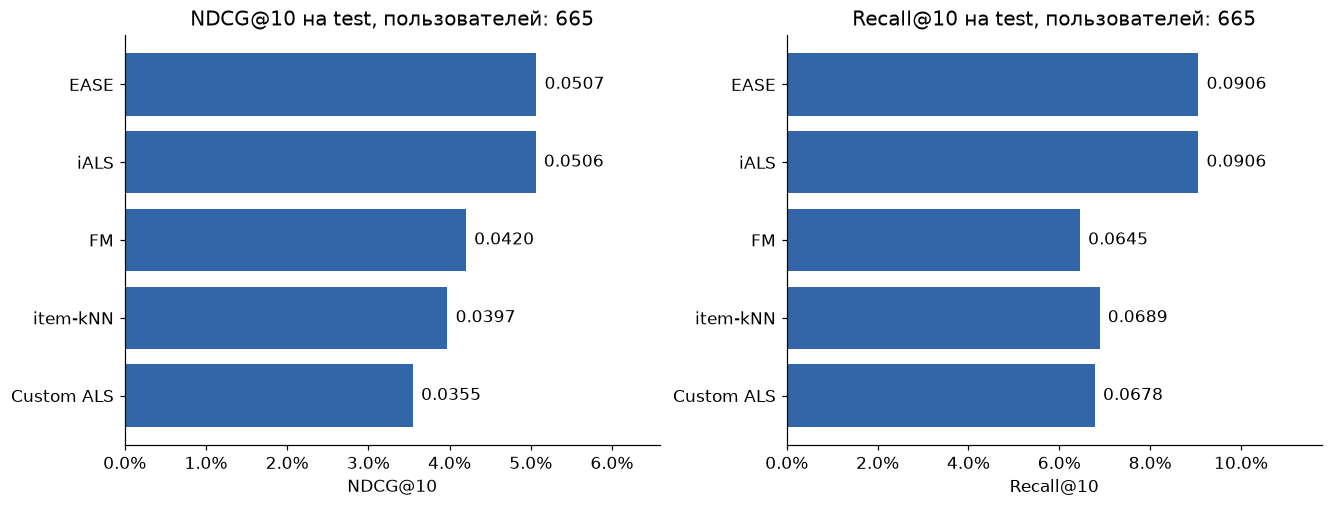

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
for a, col in zip(ax, ['NDCG@10', 'Recall@10']):
    a.barh(res['Модель'][::-1], res[col][::-1], color='#3266a8')
    a.set_xlim(0, res[col].max() * 1.3)
    a.set_title(f'{col} на test, пользователей: {len(tu):,}')
    a.set_xlabel(col)
    a.xaxis.set_major_formatter(PercentFormatter(1, decimals=1))
    for y, v in enumerate(res[col][::-1]):
        a.text(v + res[col].max() * .02, y, f'{v:.4f}', va='center')
fig.savefig('figures/results.png', bbox_inches='tight')
plt.show()

### Проверка влияния метаданных и собственного таргета

Для FM убираю категории, сохраняя выбранные на validation параметры, число эпох и seed. Для таргета дополнительно сравниваю Custom ALS с iALS при **настройках базового iALS**. Это отделяет замену таргета от разницы в выбранной регуляризации. Дополнительные эксперименты не участвуют в подборе и не меняют финальную таблицу пяти моделей.

Для разности NDCG@10 считаю парный bootstrap по одним и тем же test-пользователям: 2 000 выборок с возвращением, percentile interval 95%. Он отражает вариативность по пользователям при фиксированном обучении и не учитывает вариативность других seed или временных границ.

In [12]:
m0 = FM(**best['FM'], meta=False).fit(br, cats)
z0, s0 = evaluate(m0, tu, tq, br)
if best['Custom ALS'] == best['iALS']:
    zm = res.set_index('Модель').loc['Custom ALS', ['Recall@10', 'NDCG@10']].to_dict()
    sm = scores['Custom ALS']
else:
    mm = CustomALS(**best['iALS']).fit(br)
    zm, sm = evaluate(mm, tu, tq, br)

ab = pd.DataFrame([
    {'Вариант': 'FM только ID', **z0},
    {'Вариант': 'FM с категориями', **res.set_index('Модель').loc['FM', ['Recall@10', 'NDCG@10']].to_dict()},
    {'Вариант': 'iALS', **res.set_index('Модель').loc['iALS', ['Recall@10', 'NDCG@10']].to_dict()},
    {'Вариант': 'Custom ALS, настройки iALS', **zm}
])
ci = pd.DataFrame([
    {'Сравнение': 'FM: категории минус ID', **interval(s0, scores['FM'])},
    {'Сравнение': 'Custom ALS минус iALS, одинаковые настройки', **interval(scores['iALS'], sm)}
])
display(ab.round(5))
display(ci.round(5))
ab.to_csv('ablations.csv', index=False)
ci.to_csv('intervals.csv', index=False)

,Вариант,Recall@10,NDCG@10
0,FM только ID,0.06156,0.03362
1,FM с категориями,0.06454,0.04202
2,iALS,0.09059,0.05060
3,"Custom ALS, настройки iALS",0.06783,0.03549


,Сравнение,разность,нижняя 95%,верхняя 95%
0,FM: категории минус ID,0.00840,-0.00260,0.01882
1,"Custom ALS минус iALS, одинаковые настройки",-0.01511,-0.02498,-0.00643


### Пример персональных рекомендаций

Показываю одного пользователя из общей test-когорты, выбранного по позиции, без подбора удачного примера. В колонке «В test ≥4» отмечаю совпадение с будущим релевантным товаром. Список иллюстрирует поведение, выводы делаю по всей когорте.

In [13]:
u = int(tu[0])
print('Внутренний ID пользователя:', u)
hist = tv[tv.u == u].sort_values('t').tail(8).merge(items[['item', 'title']], on='item', validate='many_to_one')
display(hist[['title', 'r']].rename(columns={'title': 'Последние известные товары', 'r': 'Оценка'}))
name = res.iloc[0]['Модель']
j = recommend(mods[name], [u], br)[0]
example = items.iloc[j][['title', 'cats']].copy()
example.insert(0, 'Позиция', np.arange(1, 11))
example['В test ≥4'] = [int(i) in tq[u] for i in j]
print('Модель:', name)
display(example.reset_index(drop=True))

Внутренний ID пользователя: 13


,Последние известные товары,Оценка
0,B000P46NMK,2.0
1,B0016BVYA2,1.0
2,B001E8VB3C,5.0
3,B0010AYJXI,4.0
4,B0058SHMXM,5.0
5,B0050SYYTK,5.0
6,B003S9WJ9A,5.0
7,B0050SYUAS,5.0


Модель: EASE


,Позиция,title,cats,В test ≥4
0,1,B000UW21A0,"[Games, PlayStation 3]",False
1,2,B004EQCCI4,"[Games, PlayStation 3]",False
2,3,B000OLXX86,"[Games, Xbox 360]",False
3,4,B00269DXCK,"[Games, Xbox 360]",False
4,5,B00269QLI8,"[Games, Xbox 360]",False
5,6,B002CZ38KA,"[Games, PlayStation 3]",False
6,7,B000B9RI14,"[Accessories, Computers & Accessories, Electronics, Gift Cards, LIVE, Points & Currenc...",False
7,8,B001SH7YMG,"[Games, Xbox 360]",False
8,9,B002I0J4VQ,[PlayStation 3],False
9,10,B0050SYUSU,"[Games, Kids & Family, Xbox 360]",False


## 6. Выводы

In [14]:
top = res.iloc[0]
rr = res.set_index('Модель')
dc = float(rr.loc['Custom ALS', 'NDCG@10'] - rr.loc['iALS', 'NDCG@10'])
dm = float(rr.loc['FM', 'NDCG@10'] - z0['NDCG@10'])
ic = ci.iloc[1]
im = ci.iloc[0]
display(Markdown(
    f"В этом запуске лучший NDCG@10 у **{top['Модель']}**: **{top['NDCG@10']:.4f}**, "
    f"Recall@10 = **{top['Recall@10']:.4f}**. Выбранные параметры: `{top['Параметры']}`. "
    f"Это результат среди заданных вариантов, а не утверждение о лучшем методе вообще.\n\n"
    f"Собственный таргет изменил NDCG@10 относительно отдельно настроенного iALS на **{dc:+.4f}**. "
    f"При одинаковых параметрах разность равна **{ic['разность']:+.4f}**, "
    f"парный bootstrap 95%: [{ic['нижняя 95%']:+.4f}; {ic['верхняя 95%']:+.4f}]. "
    + ("Интервал включает ноль: уверенного преимущества по этой проверке нет." if ic['нижняя 95%'] <= 0 <= ic['верхняя 95%']
       else "Интервал не включает ноль; направление разности устойчиво при пересэмплировании этих пользователей.")
    + f"\n\nДобавление категорий к FM изменило NDCG@10 на **{dm:+.4f}**, "
    f"95% интервал: [{im['нижняя 95%']:+.4f}; {im['верхняя 95%']:+.4f}]. "
    + ("Точечная оценка с категориями выше." if dm > 0 else "Точечная оценка с категориями не выше.")
    + (" Интервал включает ноль: устойчивое улучшение по этой проверке не установлено." if im['нижняя 95%'] <= 0 <= im['верхняя 95%'] else " Интервал не включает ноль.")
    + " Сравнение относится к выбранной сетке и одному seed. Отдельного подбора для FM без метаданных не было."
))

out = {'config': cfg, 'hashes': hashes, 'interactions': len(df),
       'users': shape[0], 'items': shape[1], 'validation_users': len(vu),
       'test_users': len(tu), 'best': best, 'results': res.to_dict(orient='records')}
Path('run.json').write_text(json.dumps(out, ensure_ascii=False, indent=2), encoding='utf-8');

В этом запуске лучший NDCG@10 у **EASE**: **0.0507**, Recall@10 = **0.0906**. Выбранные параметры: `{"reg": 100}`. Это результат среди заданных вариантов, а не утверждение о лучшем методе вообще.

Собственный таргет изменил NDCG@10 относительно отдельно настроенного iALS на **-0.0151**. При одинаковых параметрах разность равна **-0.0151**, парный bootstrap 95%: [-0.0250; -0.0064]. Интервал не включает ноль; направление разности устойчиво при пересэмплировании этих пользователей.

Добавление категорий к FM изменило NDCG@10 на **+0.0084**, 95% интервал: [-0.0026; +0.0188]. Точечная оценка с категориями выше. Интервал включает ноль: устойчивое улучшение по этой проверке не установлено. Сравнение относится к выбранной сетке и одному seed. Отдельного подбора для FM без метаданных не было.

Ограничения:

- Отзыв появляется позже фактического знакомства с товаром. Timestamp отзыва — приближение момента взаимодействия; оценка полезности рекомендаций здесь офлайн.
- В исходном 5-core пользователи и товары уже отфильтрованы авторами по всему периоду. Поэтому исходная выборка содержит смещение в сторону активных участников. Дополнительный отбор сделан только по train, но не устраняет исходное смещение.
- После всех фильтров осталось 110 416 отзывов и 14 040 пользователей. В test только 1 484 отзыва и 665 оцениваемых пользователей; такой размер ограничивает точность сравнения близких методов.
- Каталог ограничен популярными в train товарами, cold-start и новые релизы вне каталога не рассматриваются. Оценка не характеризует весь ассортимент Amazon.
- В исходных метаданных мало названий: в выбранном каталоге название отсутствует у 98.5% товаров. В примере для них показан ASIN, категории при этом есть почти у всех.
- Использую статические категории платформ/типов товара из архивных метаданных как свойства, известные при появлении товара. Исторических снимков категорий нет, точность этого предположения проверить нельзя. Изменяющиеся популярность, цены, helpfulness и графы покупок не включены.
- Ненаблюдаемый товар не обязательно неинтересен. Это особенно влияет на FM с negative sampling и на смысл нулей в ALS/EASE.
- Сетка небольшая, одна временная граница для каждого этапа и один seed обучения. Bootstrap не заменяет повторные обучения. Выводы ограничены этим протоколом.

Реализации обучения, scores и top-10 находятся в `models/` и `utils.py`. Итоговые CSV и `run.json` формируются ячейками, их можно сверить с выводами ноутбука.